# Assignment 2, Part 2: Pedestrians on Eindhoven Centraal

In this notebook you model the future motion of pedestrians on platforms 3 and 4 of Eindhoven Centraal. Given the first 10 observed frames of a scene, you generate the remaining 20 frames for all pedestrians using conditional flow matching with time bundling.

You implement and compare two models:
1. a model with an uninformed Gaussian prior on the future velocities;
2. a model with an informed, data dependent prior.

The focus is not on model performance, but on an architecture that fits the problem formulation and on the comparison between the two priors. Every group member must be able to explain the model design and interpret the results. The full task description is in Section 2 of the assignment PDF.

In [1]:
import gdown
from pathlib import Path
import pickle
import torch
from torch.utils.data import Dataset
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from lightning import LightningDataModule, LightningModule, Trainer
import math
import warnings
import matplotlib.pyplot as plt
import numpy as np

/home/lrubega/venvs/ml4sci/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Dataset

The dataset contains 100,000 samples. Each sample is a scene with 5 to 100 pedestrians, stored as an array of shape `(N, 30, 2)`: the 2D positions in metres of `N` pedestrians over 30 frames, spaced $\Delta t = 0.5$ s apart (15 s in total). Every pedestrian is present in all 30 frames.

The cell below downloads the data (about 290 MB).

In [2]:
drive_link = "https://drive.google.com/file/d/1sU_gti1xg2AB_SQINy_cZZm4jxE9lbIm/view?usp=drive_link"

DATA_PATH = Path("eindhoven_centraal.pkl")

if not DATA_PATH.exists():

    print("Downloading dataset...")

    gdown.download(
        url=drive_link,
        output=str(DATA_PATH),
        quiet=False,
    )

    print(
        "Download complete:",
        DATA_PATH,
    )

else:
    print(
        "Dataset already available:",
        DATA_PATH,
    )

Dataset already available: eindhoven_centraal.pkl


## Data loading and graph construction

`PedestriansDataset` loads the samples and turns each one into a graph:

* **Nodes** are pedestrians. The node features `x` are the full trajectories, with shape `(N, 30, 2)`.
* **Edges** are fixed over time: the same `edge_index` of shape `(2, E)` is used for every frame. The example graph is fully connected without self loops, so $E = N(N-1)$.

After batching with the PyG `DataLoader`, `x` has shape `(sum N, 30, 2)`, the edges of each scene are offset so they never connect different scenes, and `batch` gives the scene index of every pedestrian.

A fully connected graph grows with $N^2$ and connects pedestrians that are far apart and do not interact. You can and should implement a less connected graph in `make_edge_index`, for example a radius or k nearest neighbour graph. Such a graph may only be built from the observed frames 0 to 9, since the target frames are not available at inference.

`GraphDataModule` splits the samples randomly at sample level with a fixed seed, so no scene appears in more than one split. The test set must contain at least 1,000 samples; a larger test set is preferred. Normalization statistics must be computed on the training split only.

In [ ]:
class PedestriansDataset(Dataset):
    """Pedestrian scenes as graphs with an edge connectivity that is fixed over time.

    Every sample is one scene with N pedestrians over F = 30 frames. Nodes are pedestrians
    and the node features are their full trajectories:
        x:          (N, F, 2)   positions in metres
        edge_index: (2, E)      edges between pedestrians, shared by all frames

    After batching with the PyG DataLoader:
        x:          (sum N, F, 2)
        edge_index: (2, sum E)  offset per scene, so edges never cross scenes
        batch:      (sum N,)    scene index of every pedestrian
    """

    def __init__(self, path, n_samples=None, T_cond=10):
        self.T_cond = T_cond
        self.raw_data = self._load_data(path)
        if n_samples is not None:
            self.raw_data = self.raw_data[:n_samples]
        print(f"Using {len(self.raw_data)} samples.")

    def _load_data(self, path):
        with open(path, "rb") as f:
            data = pickle.load(f)
        data = [torch.tensor(sample, dtype=torch.float32) for sample in data]
        print(
            f"\nLoaded {len(data)} samples from {path}, containing in total "
            f"{sum(x.shape[0] for x in data)} trajectories of {data[0].shape[1]} frames.\n"
        )
        return data

    def make_edge_index(self, sample, k=8):
        """kNN graph: edges j -> i from the k closest pedestrians at frame 9, the last observed frame.

        Only uses the observed frames, so nothing leaks from the future. Shape: (2, N * min(k, N - 1)).
        """
        p_last = sample[:, self.T_cond - 1]                  # (N, 2)
        dist = torch.cdist(p_last, p_last)
        dist.fill_diagonal_(float("inf"))
        k = min(k, sample.shape[0] - 1)
        src = dist.topk(k, dim=1, largest=False).indices      # (N, k) closest pedestrians
        dst = torch.arange(sample.shape[0])[:, None].expand(-1, k)
        return torch.stack([src.reshape(-1), dst.reshape(-1)])

    def __len__(self):
        return len(self.raw_data)

    def __getitem__(self, idx):
        sample = self.raw_data[idx]  # (N, F, 2)
        N = sample.shape[0]
        return Data(x=sample, edge_index=self.make_edge_index(sample), num_nodes=N)


class GraphDataModule(LightningDataModule):
    """Random split at sample level, so no scene appears in more than one split."""

    def __init__(self, dataset, train_split, val_split, test_split, batch_size=8, seed=42, min_test_size=1000):
        super().__init__()
        if not math.isclose(train_split + val_split + test_split, 1.0):
            raise ValueError("train_split, val_split and test_split must sum to 1.")
        self.batch_size = batch_size
        self.seed = seed
        self.train_data, self.val_data, self.test_data = self.split_data(dataset, train_split, val_split)

        print(
            f"Split with seed {seed}: {len(self.train_data)} train, "
            f"{len(self.val_data)} validation, {len(self.test_data)} test samples."
        )
        if len(self.test_data) < min_test_size:
            warnings.warn(
                f"The test set contains {len(self.test_data)} samples, "
                f"but the assignment requires at least {min_test_size}."
            )

    def split_data(self, dataset, train_split, val_split):
        total_size = len(dataset)
        train_size = int(total_size * train_split)
        val_size = int(total_size * val_split)
        test_size = total_size - train_size - val_size

        return torch.utils.data.random_split(
            dataset,
            [train_size, val_size, test_size],
            generator=torch.Generator().manual_seed(self.seed),
        )

    def train_dataloader(self):
        return DataLoader(self.train_data, batch_size=self.batch_size, shuffle=True)  

    def val_dataloader(self):
        return DataLoader(self.val_data, batch_size=self.batch_size)  

    def test_dataloader(self):
        return DataLoader(self.test_data, batch_size=self.batch_size)  

    def predict_dataloader(self):
        return DataLoader(self.test_data, batch_size=self.batch_size) 

## Configuration

`n_samples` limits the number of samples for faster development. Make sure the final test set contains at least 1,000 samples, and report the seed and the size of each split.

In [4]:
T_cond = 10

n_samples = 10000  # Limit to a number of samples for faster training during development

dataset = PedestriansDataset(
    DATA_PATH, n_samples=n_samples, T_cond=T_cond
) 

data_module = GraphDataModule(
    dataset, train_split=0.7, val_split=0.1, test_split=0.2, batch_size=16
)


Loaded 100000 samples from eindhoven_centraal.pkl, containing in total 2358008 trajectories of 30 frames.

Using 10000 samples.
Split with seed 42: 7000 train, 1000 validation, 2000 test samples.


## Visualization
This method can be used to visualize the pedestrian trajectories. Use it to double check if your generated samples are realistic.

Make sure you download the background image: https://github.com/vlamen/ml4sci-2026/blob/main/assignments/Eindhoven_centraal_platform_3_4.png

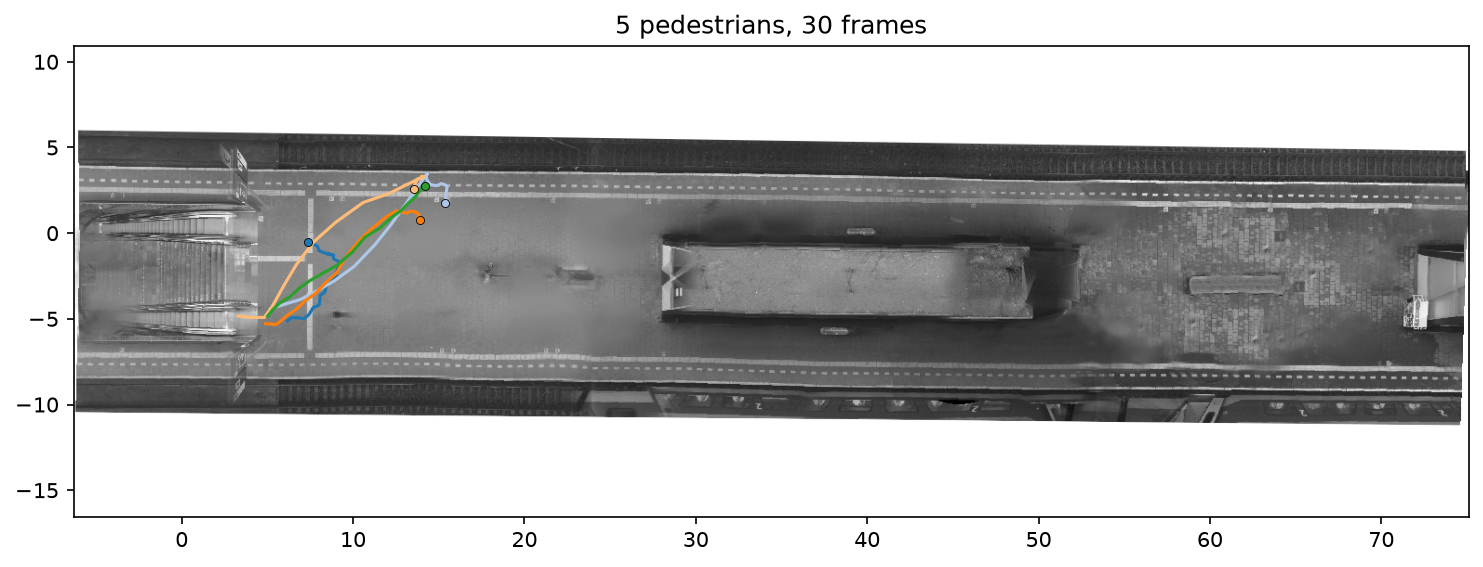

In [5]:
EXTENT = (-6.309, 75.091, -16.539, 10.909)  # (left, right, bottom, top) of the background image in metres


def plot_sample(sample, background_path="Eindhoven_centraal_platform_3_4.png", ax=None,
                cmap_name="tab20", figsize=(12, 4.5), dpi=150):
    """Plot all trajectories of one data sample on the station background.

    sample: (N, F, 2) positions of N pedestrians over F frames, as a numpy array or torch tensor.
    The x and y axes of the data are swapped to match the background image.
    Each pedestrian gets its own color; the dot marks the final position.
    """
    if isinstance(sample, torch.Tensor):
        sample = sample.detach().cpu().numpy()
    traj = np.asarray(sample)[..., [1, 0]]  # Swap x and y

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    else:
        fig = ax.figure

    ax.imshow(plt.imread(background_path), extent=EXTENT, origin="upper", zorder=0)
    ax.set_xlim(EXTENT[0], EXTENT[1])
    ax.set_ylim(EXTENT[2], EXTENT[3])

    cmap = plt.get_cmap(cmap_name)
    for i, t in enumerate(traj):
        color = cmap(i % cmap.N)
        ax.plot(t[:, 0], t[:, 1], color=color, lw=1.5, zorder=1)
        ax.scatter(t[-1, 0], t[-1, 1], color=color, s=15, edgecolors="black", linewidths=0.4, zorder=2)

    ax.set_title(f"{traj.shape[0]} pedestrians, {traj.shape[1]} frames")
    return fig, ax

plot_sample(dataset[0].x)
plt.show()

## Model architecture

Your model must capture patterns over **space**, the interactions between pedestrians, and over **time**, how the motion of each pedestrian evolves over the frames. As discussed in Practical 4, message passing handles space but not time, and flattening all frames into an MLP ignores temporal order and locality. Design an architecture that handles both axes, for example message passing over pedestrians combined with convolutions or attention over time.

Use the same architecture, training budget and sampler for both models, so that the prior is the only difference between them.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from lightning.pytorch import seed_everything
from lightning.pytorch.callbacks import ModelCheckpoint

DT = 0.5                    # seconds between frames
H, K = T_cond, 30 - T_cond  # observed and generated frames
HIDDEN = 64
N_BLOCKS = 4
N_HEADS = 4                 # attention heads in the temporal blocks
SIGMA = 1.0                 # prior noise, same for both priors
N_EULER_STEPS = 16          # Euler steps for sampling
EPOCHS = 30                 # same for both models
LR = 1e-3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def compute_normalization(train_data):
    """Normalization statistics, from the training split only."""
    vel, rel, pos = [], [], []
    for data in train_data:
        p = data.x                                    # (N, 30, 2)
        vel.append(((p[:, 1:] - p[:, :-1]) / DT).reshape(-1, 2))
        rel.append((p[:, :H] - p[:, H - 1:H]).reshape(-1, 2))
        pos.append(p[:, H - 1])
    vel, rel, pos = torch.cat(vel), torch.cat(rel), torch.cat(pos)
    return {"vel_mean": vel.mean(0), "vel_std": vel.std(0),
            "rel_std": rel.std(0), "pos_mean": pos.mean(0), "pos_std": pos.std(0)}


def tau_embedding(tau, dim=32):
    """Sinusoidal embedding of tau."""
    freqs = torch.exp(torch.linspace(0, math.log(1000), dim // 2, device=tau.device))
    args = tau[:, None] * freqs[None]
    return torch.cat([args.cos(), args.sin()], dim=-1)


class NeuralMessagePassingLayer(nn.Module):
    """Message passing layer from Practical 4."""

    def __init__(self, in_features, in_edge_features, hidden_dim, out_features):
        super().__init__()
        self.message_mlp = nn.Sequential(
            nn.Linear(2 * in_features + in_edge_features, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )
        self.node_mlp = nn.Sequential(
            nn.Linear(in_features + hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, out_features),
        )

    def forward(self, x, edge_index, edge_attr):
        source_nodes, target_nodes = edge_index
        messages = self.message_mlp(torch.cat([x[source_nodes], x[target_nodes], edge_attr], dim=-1))

        aggregated_messages = torch.zeros(x.size(0), messages.size(-1), device=x.device)
        aggregated_messages.index_reduce_(0, target_nodes, messages, reduce="mean", include_self=False)

        return self.node_mlp(torch.cat([x, aggregated_messages], dim=-1))


class TemporalBlock(nn.Module):
    """Self-attention over the 30 frames of each pedestrian, then an MLP, both residual.

    Every frame sees every other frame, so frame 29 also sees the observed frames.
    The frame embedding acts as the positional encoding.
    """

    def __init__(self, dim, n_heads=N_HEADS):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, n_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, 2 * dim), nn.SiLU(), nn.Linear(2 * dim, dim))

    def forward(self, h):                             # h: (sum N, 30, dim)
        y = self.norm1(h)
        h = h + self.attn(y, y, y, need_weights=False)[0]
        return h + self.mlp(self.norm2(h))


class SpatialBlock(nn.Module):
    """Message passing between pedestrians, with the same weights for every frame."""

    def __init__(self, dim, edge_dim):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.mp = NeuralMessagePassingLayer(dim, edge_dim, dim, dim)

    def forward(self, h, edge_index, edge_attr):      # h: (sum N, F, dim), edge_attr: (E, F, edge_dim)
        n, f, d = h.shape
        y = self.norm(h).transpose(0, 1).reshape(f * n, d)            # node i at frame t -> index t * n + i
        offsets = (torch.arange(f, device=h.device) * n).repeat_interleave(edge_index.shape[1])
        frame_edges = edge_index.repeat(1, f) + offsets                # the same graph in every frame
        frame_attr = edge_attr.transpose(0, 1).reshape(-1, edge_attr.shape[-1])
        y = self.mp(y, frame_edges, frame_attr)
        return h + y.reshape(f, n, d).transpose(0, 1)


class SpaceTimeVelocityField(nn.Module):
    """Velocity field v_theta(x_tau, tau | c) on the pedestrians x frames grid.

    Frames 0-9 hold the observed position (relative to frame 9) and velocity, frames 10-29 hold x_tau.
    Temporal blocks mix the frames of one pedestrian, spatial blocks mix neighbouring pedestrians.
    For frames 10-29 the edge features come from the positions implied by x_tau.
    """

    IN_FEATURES = 7   # relative position (2), velocity (2), observed flag (1), absolute position at frame 9 (2)
    EDGE_FEATURES = 3  # relative position of the neighbour (2) and its distance (1)

    def __init__(self, hidden=HIDDEN, n_blocks=N_BLOCKS, tau_dim=32):
        super().__init__()
        self.tau_dim = tau_dim
        self.input = nn.Linear(self.IN_FEATURES, hidden)
        self.frame_embedding = nn.Parameter(torch.zeros(H + K, hidden))
        self.tau_mlp = nn.Sequential(nn.Linear(tau_dim, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.temporal = nn.ModuleList([TemporalBlock(hidden) for _ in range(n_blocks)])
        self.spatial = nn.ModuleList([SpatialBlock(hidden, self.EDGE_FEATURES) for _ in range(n_blocks)])
        self.tau_proj = nn.ModuleList([nn.Linear(hidden, hidden) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.LayerNorm(hidden), nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 2))

    def forward(self, x_tau, tau, cond):
        """x_tau: (sum N, K, 2), tau: (sum N,), cond: dict from PedestrianFlowModel.condition."""
        n = x_tau.shape[0]
        future = torch.cat([torch.zeros(n, K, 2, device=x_tau.device), x_tau,
                            torch.zeros(n, K, 1, device=x_tau.device)], dim=-1)
        frames = torch.cat([cond["observed"], future], dim=1)      # (sum N, 30, 5)
        static = cond["position"][:, None].expand(-1, H + K, -1)                 # (sum N, 30, 2)
        h = self.input(torch.cat([frames, static], dim=-1)) + self.frame_embedding

        src, dst = cond["edge_index"]
        vel = x_tau * cond["vel_std"] + cond["vel_mean"]       # (sum N, K, 2) in m/s
        p_future = cond["p9"][:, None] + DT * torch.cumsum(vel, dim=1)            # positions implied by x_tau
        offset = p_future[src] - p_future[dst]                                     # (E, K, 2)
        future_attr = torch.cat([offset / cond["rel_std"], offset.norm(dim=-1, keepdim=True)], dim=-1)
        edge_attr = torch.cat([cond["edge_attr"], future_attr], dim=1)             # (E, 30, 3)

        t = self.tau_mlp(tau_embedding(tau, self.tau_dim))       # (sum N, hidden)
        for temporal, spatial, tau_proj in zip(self.temporal, self.spatial, self.tau_proj):
            h = h + tau_proj(t)[:, None]
            h = temporal(h)
            h = spatial(h, cond["edge_index"], edge_attr)
        return self.head(h[:, H:])     # (sum N, K, 2)


class PedestrianFlowModel(LightningModule):
    """Flow matching with time bundling: all 20 future velocities in one call.

    Part I and Part II only differ in `sample_prior`.
    """

    def __init__(self, norm, sigma=SIGMA, n_steps=N_EULER_STEPS, lr=LR, epochs=EPOCHS):
        super().__init__()
        self.vf = SpaceTimeVelocityField()
        self.sigma, self.n_steps, self.lr, self.epochs = sigma, n_steps, lr, epochs
        for name, value in norm.items():
            self.register_buffer(name, value.clone())

    def condition(self, batch):
        """Everything the model may use, from frames 0-9 only."""
        p = batch.x[:, :H]               # (sum N, 10, 2)
        vel = torch.zeros_like(p)
        vel[:, 1:] = (p[:, 1:] - p[:, :-1]) / DT                                 # v^0 is unknown, left at 0
        vel_n = (vel - self.vel_mean) / self.vel_std
        vel_n[:, 0] = 0.0
        rel = (p - p[:, -1:]) / self.rel_std
        observed = torch.cat([rel, vel_n, torch.ones_like(p[..., :1])], dim=-1)  # (sum N, 10, 5)

        p9 = p[:, -1]
        edge_index = batch.edge_index       # kNN graph from make_edge_index
        src, dst = edge_index
        offset = p[src] - p[dst]              # (E, 10, 2), observed frames only
        edge_attr = torch.cat([offset / self.rel_std, offset.norm(dim=-1, keepdim=True)], dim=-1)
        return {"observed": observed, "position": (p9 - self.pos_mean) / self.pos_std,
                "last_velocity": vel_n[:, -1], "edge_index": edge_index, "edge_attr": edge_attr,
                "p9": p9, "vel_mean": self.vel_mean, "vel_std": self.vel_std, "rel_std": self.rel_std}

    def target(self, batch):
        """Normalized future velocities v^10, ..., v^29, shape (sum N, K, 2)."""
        p = batch.x
        vel = (p[:, H:] - p[:, H - 1:-1]) / DT
        return (vel - self.vel_mean) / self.vel_std

    def sample_prior(self, cond):
        """Uninformed prior N(0, sigma^2 I)."""
        n = cond["observed"].shape[0]
        return self.sigma * torch.randn(n, K, 2, device=self.vel_mean.device)

    def to_positions(self, x1, batch):
        """Normalized velocities -> positions in metres, p^{9+k} = p^9 + dt * sum_{j<=k} v^{9+j}."""
        vel = x1 * self.vel_std + self.vel_mean
        return batch.x[:, H - 1:H] + DT * torch.cumsum(vel, dim=1)

    def flow_matching_loss(self, batch):
        cond = self.condition(batch)
        x1 = self.target(batch)
        x0 = self.sample_prior(cond)
        tau = torch.rand(batch.num_graphs, device=x1.device)[batch.batch]       # one tau per scene
        x_tau = (1 - tau[:, None, None]) * x0 + tau[:, None, None] * x1
        v = self.vf(x_tau, tau, cond)
        return F.mse_loss(v, x1 - x0)

    def training_step(self, batch, batch_idx):
        loss = self.flow_matching_loss(batch)
        self.log("train_loss", loss, batch_size=batch.num_graphs, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss = self.flow_matching_loss(batch)
        self.log("val_loss", loss, batch_size=batch.num_graphs, prog_bar=True)

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(self.parameters(), lr=self.lr, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.epochs)
        return [optimizer], [scheduler]

    @torch.no_grad()
    def sample(self, batch, M=1, n_steps=None):
        """M futures per pedestrian, as positions in metres of shape (M, sum N, K, 2).

        Starts from new prior samples and takes Euler steps from tau = 0 to 1.
        """
        self.eval()
        batch = batch.to(self.vel_mean.device)
        n_steps = n_steps or self.n_steps
        cond = self.condition(batch)
        futures = []
        for _ in range(M):
            x = self.sample_prior(cond)
            for i in range(n_steps):
                tau = torch.full((x.shape[0],), i / n_steps, device=x.device)
                x = x + self.vf(x, tau, cond) / n_steps
            futures.append(self.to_positions(x, batch))
        return torch.stack(futures)


def train_flow_model(model, name, seed=42):
    """Train with the same seed and budget for both priors and keep the best validation checkpoint."""
    seed_everything(seed)
    checkpoint = ModelCheckpoint(monitor="val_loss", mode="min", filename=name + "-{epoch}-{val_loss:.4f}")
    trainer = Trainer(max_epochs=model.epochs, gradient_clip_val=1.0, callbacks=[checkpoint], log_every_n_steps=50)
    trainer.fit(model, datamodule=data_module)
    model.load_state_dict(torch.load(checkpoint.best_model_path, map_location="cpu")["state_dict"])
    return model.to(DEVICE).eval()


seed_everything(42)
norm = compute_normalization(data_module.train_data)
print({k: v.tolist() for k, v in norm.items()})

[rank: 0] Seed set to 42


{'vel_mean': [0.02959815040230751, -0.0365561880171299], 'vel_std': [0.2190628945827484, 0.6856278777122498], 'rel_std': [0.472485214471817, 1.809843897819519], 'pos_mean': [-2.219651937484741, 30.2630615234375], 'pos_std': [2.8882787227630615, 19.859655380249023]}


## Part I: Uninformed Gaussian prior

Train a conditional flow matching model that generates the velocities of frames 10 to 29, conditioned on frames 0 to 9, using the independent coupling

$$\pi(x_0, x_1 \mid c) = p_0(x_0)\,p_1(x_1 \mid c), \qquad p_0 = \mathcal{N}(0, \sigma^2 I).$$

All 20 frames are generated in a single model call. Positions are recovered by summing the generated velocities, starting from the last observed position.

In [7]:
model_uninformed = train_flow_model(PedestrianFlowModel(norm), name="uninformed")

sample_uninformed = lambda batch, M, n_steps: model_uninformed.sample(batch, M, n_steps)
prior_uninformed = lambda batch: model_uninformed.sample_prior(model_uninformed.condition(batch.to(DEVICE)))

[rank: 0] Seed set to 42


/home/lrubega/venvs/ml4sci/lib/python3.12/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/lrubega/venvs/ml4sci/lib/python3.12/site-packa ...
GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


/home/lrubega/venvs/ml4sci/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA A100-SXM4-40GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=30` reached.


## Part II: Informed prior

Train a second model using a data dependent coupling

$$\pi(x_0, x_1 \mid c) = p_0(x_0 \mid c)\,p_1(x_1 \mid c).$$

The prior may only use the observed frames 0 to 9, so that $x_0 \perp x_1 \mid c$. It must remain stochastic and be sampled in the same way during training and inference.

In [8]:
def fit_horizon_gamma(train_data, norm):
    """Least-squares gamma_k to predict v^{9+k} from v^9, in normalized units, on the training split.

    This gives the lowest transport cost for a prior of this form. gamma_k = 0 is the uninformed prior.
    """
    num, den = torch.zeros(K), torch.zeros(())
    for data in train_data:
        p = data.x
        vel = ((p[:, 1:] - p[:, :-1]) / DT - norm["vel_mean"]) / norm["vel_std"]   # vel[:, t - 1] = v^t
        v9, future = vel[:, H - 2], vel[:, H - 1:]                                 # (N, 2), (N, K, 2)
        num += (future * v9[:, None]).sum(dim=(0, 2))
        den += (v9 ** 2).sum()
    return num / den


class InformedPriorFlowModel(PedestrianFlowModel):
    """Same model, training and sampler as Part I; only the prior changes.

    x_0 = gamma_k * v^9 + sigma * eps: each pedestrian starts from its last observed velocity,
    scaled down more for frames further ahead. Only uses the observed frames.
    """

    def __init__(self, norm, gamma, **kwargs):
        super().__init__(norm, **kwargs)
        self.register_buffer("gamma", gamma.clone())

    def sample_prior(self, cond):
        mean = self.gamma[None, :, None] * cond["last_velocity"][:, None]           # (sum N, K, 2)
        return mean + self.sigma * torch.randn_like(mean)


gamma = fit_horizon_gamma(data_module.train_data, norm)
print("gamma_k:", [round(g, 3) for g in gamma.tolist()])

model_informed = train_flow_model(InformedPriorFlowModel(norm, gamma), name="informed")

sample_informed = lambda batch, M, n_steps: model_informed.sample(batch, M, n_steps)
prior_informed = lambda batch: model_informed.sample_prior(model_informed.condition(batch.to(DEVICE)))
target_fn = lambda batch: model_informed.target(batch.to(DEVICE))

[rank: 0] Seed set to 42


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=30` reached.


## Evaluation

For every test sample, generate $M = 20$ futures with each model. All metrics are computed on frames 10 to 29 only.

**Pointwise metrics.** Report ADE, FDE, $\text{min}_{20}$ ADE and $\text{min}_{20}$ FDE. ADE and FDE are averaged over all pedestrians, samples and generated futures. For the $\text{min}_{20}$ metrics, the best future is selected per data sample based on the error averaged over all its pedestrians, not per pedestrian.

**Distributional metrics.** Plot histogram densities of the ground truth and both models for velocity magnitude, acceleration magnitude, tortuosity and distance to the closest neighbour within the same frame.

The exact definitions are given in the evaluation section of the assignment PDF. You are of course allowed to use code from the practicals

In [ ]:
FUTURE_FRAMES = np.arange(H, H + K)  # frames 10, ..., 29
MODEL_COLORS = ["C1", "C2"]          # uninformed, informed (ground truth is C0)


def collect_futures(sample_fn, loader, M=20, n_steps=None, max_samples=None, seed=0):
    """Generate M futures for every scene and split them per scene.

    sample_fn(batch, M, n_steps) returns positions in metres for frames 10-29, shape (M, sum N, K, 2).
    Returns the ground truth (N, 30, 2) and generated (M, N, K, 2) per scene, as numpy.
    """
    torch.manual_seed(seed)
    gt, gen = [], []
    for batch in loader:
        with torch.no_grad():
            futures = sample_fn(batch, M, n_steps)
        futures = torch.as_tensor(futures).detach().cpu().numpy()
        x = batch.x.detach().cpu().numpy()
        ptr = batch.ptr.cpu().numpy()  # scene s owns nodes ptr[s]:ptr[s + 1]
        for s in range(len(ptr) - 1):
            gt.append(x[ptr[s]:ptr[s + 1]])
            gen.append(futures[:, ptr[s]:ptr[s + 1]])
            if max_samples is not None and len(gt) >= max_samples:
                return gt, gen
    return gt, gen


def full_trajectories(gt_scene, gen_scene=None):
    """Observed frames 0-9 plus the future frames, shape (M, N, 30, 2)."""
    if gen_scene is None:
        return gt_scene[None]
    observed = np.broadcast_to(gt_scene[None, :, :H], (gen_scene.shape[0],) + gt_scene[:, :H].shape)
    return np.concatenate([observed, gen_scene], axis=2)


def scene_kinematics(traj, dt=DT):
    """Kinematics of the generated frames (Section 2.8.2).

    Backward differences, so frame 10 uses the observed frames 8 and 9.
    """
    vel = (traj[:, :, 1:] - traj[:, :, :-1]) / dt   # vel[:, :, t - 1] = v^t
    acc = (vel[:, :, 1:] - vel[:, :, :-1]) / dt     # acc[:, :, t - 2] = a^t
    speed = np.linalg.norm(vel[:, :, H - 1:], axis=-1)                    # (M, N, K), t = 10..29
    acc_mag = np.linalg.norm(acc[:, :, H - 2:], axis=-1)                  # (M, N, K)

    distance = (speed * dt).sum(axis=-1)                                  # (M, N) path length over 9 -> 29
    net = np.linalg.norm(traj[:, :, -1] - traj[:, :, H - 1], axis=-1)    # ||p^29 - p^9||
    tortuosity = distance / np.maximum(net, 0.01)                        # (M, N)

    future = traj[:, :, H:]                                               # (M, N, K, 2)
    pair = np.linalg.norm(future[:, :, None] - future[:, None], axis=-1)  # (M, N, N, K)
    idx = np.arange(traj.shape[1])
    pair[:, idx, idx] = np.inf                                            # exclude j = i
    closest = pair.min(axis=2)                                            # (M, N, K)

    return {"speed": speed, "acceleration": acc_mag, "tortuosity": tortuosity,
            "distance": distance, "closest": closest}


def compute_kinematics(gt, gen=None):
    """Kinematics per scene, for the ground truth (gen=None) or a model."""
    if gen is None:
        return [scene_kinematics(full_trajectories(g)) for g in gt]
    return [scene_kinematics(full_trajectories(g, f)) for g, f in zip(gt, gen)]


def pooled(kin, key):
    """Pool one quantity over everything into a flat array."""
    return np.concatenate([k[key].ravel() for k in kin])


def per_frame(kin, key):
    """One quantity per frame, shape (K, n_values)."""
    return np.concatenate([np.moveaxis(k[key], -1, 0).reshape(K, -1) for k in kin], axis=1)


def pointwise_metrics(gt, gen):
    """ADE, FDE, min20 ADE and min20 FDE (Section 2.8.1), in metres."""
    ade, fde = [], []
    for g, f in zip(gt, gen):
        d = np.linalg.norm(f - g[None, :, H:], axis=-1)   # (M, N, K)
        ade.append(d.mean(axis=(1, 2)))           # ADE_{s,m}, averaged over pedestrians and frames
        fde.append(d[:, :, -1].mean(axis=1))              # FDE_{s,m}, frame 29
    ade, fde = np.stack(ade), np.stack(fde)        # (S, M)
    return {"ADE": ade.mean(), "FDE": fde.mean(),
            "min20 ADE": ade.min(axis=1).mean(), "min20 FDE": fde.min(axis=1).mean()}


HIST_PLOTS = [("speed", "Velocity magnitude [m/s]", None),
              ("acceleration", "Acceleration magnitude [m/s²]", None),
              ("tortuosity", "Tortuosity", None),
              ("closest", "Distance to closest neighbour [m]", (0.0, 2.0))]


def plot_histograms(kins, colors=("C0", "C1", "C2")):
    """Histograms of the four quantities of Section 2.8.2."""
    fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), dpi=150)
    for ax, (key, label, value_range) in zip(axs, HIST_PLOTS):
        values = {name: pooled(kin, key) for name, kin in kins.items()}
        lo, hi = value_range or np.quantile(values["Ground truth"], [0.0, 0.99])
        bins = np.linspace(lo, hi, 60)
        for i, (name, v) in enumerate(values.items()):
            style = dict(histtype="stepfilled", alpha=0.45) if i == 0 else dict(histtype="step", lw=1.6)
            ax.hist(v, bins=bins, range=(lo, hi), density=True, color=colors[i], label=name, **style)
        ax.set_xlim(lo, hi)
        ax.set_xlabel(label)
        ax.set_ylabel("Density")
        ax.grid(alpha=0.4, ls="--", lw=0.5)
        ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    return fig


test_loader = data_module.test_dataloader()
gt_test, gen_u = collect_futures(sample_uninformed, test_loader, M=20, n_steps=N_EULER_STEPS, seed=0)
_, gen_i = collect_futures(sample_informed, test_loader, M=20, n_steps=N_EULER_STEPS, seed=0)
print(f"{len(gt_test)} test samples, 20 futures each, {N_EULER_STEPS} Euler steps")

metrics = {"Uninformed prior": pointwise_metrics(gt_test, gen_u), "Informed prior": pointwise_metrics(gt_test, gen_i)}

gt_kin = compute_kinematics(gt_test)
model_kins = {"Uninformed": compute_kinematics(gt_test, gen_u), "Informed": compute_kinematics(gt_test, gen_i)}
all_kins = {"Ground truth": gt_kin, **model_kins}

2000 test samples, 20 futures each, 16 Euler steps


## Comparison

Show the four pointwise metrics for both models in a table, together with the four histograms. Explanations and interpretations of the results are written in Ans, not in this notebook.

Pointwise metrics [m]          ADE         FDE   min20 ADE   min20 FDE
Uninformed prior             0.914       1.850       0.644       1.217
Informed prior               0.919       1.860       0.646       1.221


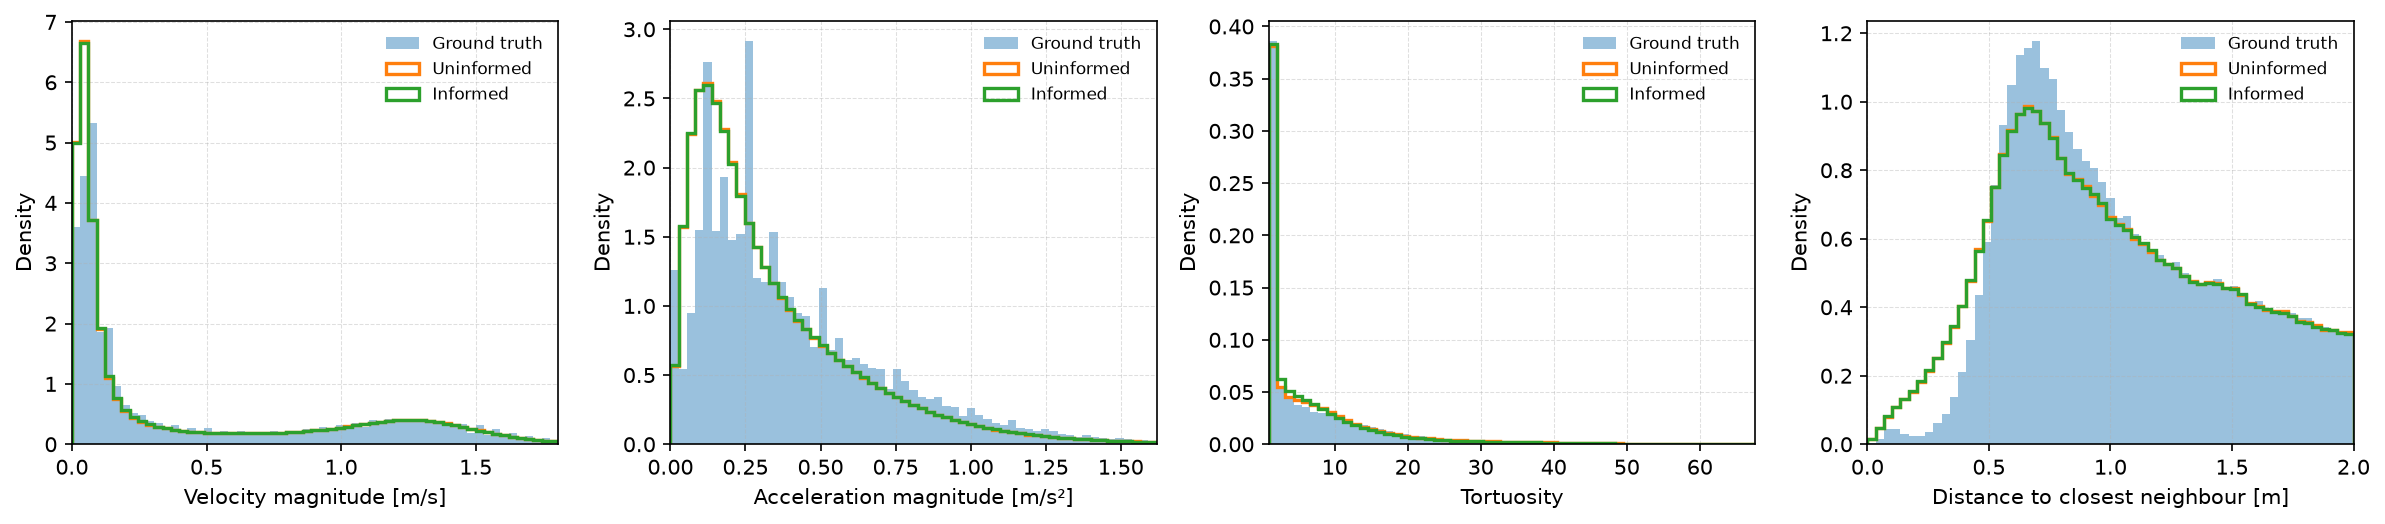

In [10]:
columns = ["ADE", "FDE", "min20 ADE", "min20 FDE"]
print(f"{'Pointwise metrics [m]':<22}" + "".join(f"{c:>12}" for c in columns))
for name, row in metrics.items():
    print(f"{name:<22}" + "".join(f"{row[c]:>12.3f}" for c in columns))

plot_histograms(all_kins)
plt.show()

In [11]:
# 1. Error over the prediction horizon

def displacement_error_per_frame(gt, gen):
    """Mean displacement error per generated frame, shape (S, K).

    Averaged within each scene first, like ADE, so the last column is FDE.
    """
    errors = []
    for g, f in zip(gt, gen):
        d = np.linalg.norm(f - g[None, :, H:], axis=-1)  # (M, N, K)
        errors.append(d.mean(axis=(0, 1)))
    return np.stack(errors)


def plot_error_over_horizon(errors, colors=None, ax=None):
    """errors: {model name: (S, K)}. Mean over scenes with the 25th-75th percentile band."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.5), dpi=150)
    for i, (name, e) in enumerate(errors.items()):
        c = (colors or MODEL_COLORS)[i]
        line, = ax.plot(FUTURE_FRAMES, e.mean(axis=0), lw=2, color=c, label=f"{name} (ADE = {e.mean():.3f} m)")
        q25, q75 = np.percentile(e, [25, 75], axis=0)
        ax.fill_between(FUTURE_FRAMES, q25, q75, color=line.get_color(), alpha=0.15, lw=0)
    ax.set_xlabel("Frame")
    ax.set_ylabel("Displacement error [m]")
    ax.set_title("Displacement error over the prediction horizon")
    ax.set_xticks(FUTURE_FRAMES[::2])
    ax.grid(alpha=0.4, ls="--", lw=0.5)
    ax.legend(frameon=False, fontsize=8)
    return ax


# 2. Distance travelled and kinematics over time

def plot_distance_and_time_profiles(kins, colors=None):
    """Histogram of the distance travelled over frames 9 -> 29, and speed and acceleration per frame
    (median with the 25th-75th percentile band). kins: {name: kinematics}, ground truth first."""
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.5), dpi=150)
    names = list(kins)
    colors = colors or [f"C{i}" for i in range(len(names))]

    dist = {n: pooled(k, "distance") for n, k in kins.items()}
    lo, hi = np.quantile(dist[names[0]], [0.005, 0.995])
    bins = np.linspace(lo, hi, 60)
    for i, (n, v) in enumerate(dist.items()):
        style = dict(histtype="stepfilled", alpha=0.5) if i == 0 else dict(histtype="step", lw=1.6)
        axs[0].hist(v, bins=bins, density=True, color=colors[i], label=f"{n} μ = {v.mean():.2f}", **style)
    axs[0].set_title("Distance travelled")
    axs[0].set_xlabel("Path length over frames 9-29 [m]")
    axs[0].set_ylabel("Density")

    for ax, key, label in [(axs[1], "speed", "Speed [m/s]"), (axs[2], "acceleration", "Acceleration [m/s²]")]:
        for i, (n, k) in enumerate(kins.items()):
            arr = per_frame(k, key)
            q25, med, q75 = np.percentile(arr, [25, 50, 75], axis=1)
            ax.fill_between(FUTURE_FRAMES, q25, q75, color=colors[i], alpha=0.15, lw=0)
            ax.plot(FUTURE_FRAMES, med, color=colors[i], lw=2, label=n)
        ax.set_title(f"{label.split(' ')[0]} over time")
        ax.set_xlabel("Frame")
        ax.set_ylabel(label)
        ax.set_xticks(FUTURE_FRAMES[::4])

    for ax in axs:
        ax.grid(alpha=0.4, ls="--", lw=0.5)
        ax.legend(frameon=False, fontsize=7)
    fig.tight_layout()
    return fig


# 3. Binned KL divergence for the four histograms

HIST_KEYS = ["speed", "acceleration", "tortuosity", "closest"]
HIST_RANGES = {"closest": (0.0, 2.0)}  # closest-neighbour histogram goes from 0 to 2 m


def binned_kl(generated, true, n_bins=60, value_range=None, pseudo_count=1.0):
    """Binned KL(generated || true) in nats, as in Practical 3.

    Equal-width bins over `value_range` (default: the central 99% of the ground truth), plus one
    overflow bin on each side. A pseudo count on the ground-truth bins keeps the KL finite.
    """
    lo, hi = value_range if value_range is not None else np.quantile(true, [0.005, 0.995])
    edges = np.concatenate(([-np.inf], np.linspace(lo, hi, n_bins + 1), [np.inf]))
    p = np.histogram(generated, bins=edges)[0].astype(float)
    q = np.histogram(true, bins=edges)[0].astype(float) + pseudo_count
    p, q = p / p.sum(), q / q.sum()
    occupied = p > 0
    return float(np.sum(p[occupied] * (np.log(p[occupied]) - np.log(q[occupied]))))


def kl_table(gt_kin, model_kins, **kwargs):
    """KL(model || ground truth) for every quantity, printed as a table."""
    table = {name: {key: binned_kl(pooled(kin, key), pooled(gt_kin, key),
                                   value_range=HIST_RANGES.get(key), **kwargs)
                    for key in HIST_KEYS}
             for name, kin in model_kins.items()}
    print(f"{'Binned KL(model || ground truth) [nats]':<40}" + "".join(f"{k:>14}" for k in HIST_KEYS))
    for name, row in table.items():
        print(f"{name:<40}" + "".join(f"{row[k]:>14.4f}" for k in HIST_KEYS))
    return table


# 4. Collision rate

COLLISION_RADIUS = 0.3  # metres, centre to centre


def collision_rate(kin, radius=COLLISION_RADIUS):
    """Fraction of pedestrian-frames with a neighbour closer than `radius`."""
    closest = pooled(kin, "closest")
    return float((closest < radius).mean())


def plot_collision_rate(kins, radii=np.linspace(0.05, 1.0, 40), radius=COLLISION_RADIUS, colors=None):
    """Collision rate for a range of radii, so we do not depend on one threshold."""
    fig, ax = plt.subplots(figsize=(6, 3.5), dpi=150)
    colors = colors or [f"C{i}" for i in range(len(kins))]
    print(f"Collision rate at r = {radius:.2f} m")
    for i, (name, kin) in enumerate(kins.items()):
        closest = np.sort(pooled(kin, "closest"))
        rates = np.searchsorted(closest, radii, side="left") / len(closest)  # fraction strictly below r
        ax.plot(radii, rates, color=colors[i], lw=2, label=name)
        print(f"  {name:<25}{collision_rate(kin, radius):.4%}")
    ax.axvline(radius, color="gray", ls=":", lw=1)
    ax.set_xlabel("Radius r [m]")
    ax.set_ylabel("Fraction of pedestrian-frames\nwith a neighbour closer than r")
    ax.set_yscale("log")
    ax.set_title("Collision rate")
    ax.grid(alpha=0.4, ls="--", lw=0.5)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    return fig


# 5. Transport cost of each prior

def prior_transport_cost(prior_fns, target_fn, loader, M=10, max_batches=50, seed=0):
    """Monte Carlo estimate of E||x_0 - x_1||^2 per pedestrian for every prior, as in Practical 4.

    prior_fns: {name: prior_fn(batch) -> x_0}, target_fn(batch) -> x_1, both normalized (sum N, K, 2).
    Run it on the training split, not the test set. Returns {name: (total, per_frame)}.
    """
    sums = {name: np.zeros(K) for name in prior_fns}
    count = 0
    for b, batch in enumerate(loader):
        if b >= max_batches:
            break
        with torch.no_grad():
            x1 = torch.as_tensor(target_fn(batch)).cpu().numpy()
            for name, prior_fn in prior_fns.items():
                torch.manual_seed(seed + b)
                x0 = np.stack([torch.as_tensor(prior_fn(batch)).cpu().numpy() for _ in range(M)])
                sums[name] += ((x0 - x1[None]) ** 2).sum(axis=-1).mean(axis=0).sum(axis=0)  # (K,)
        count += x1.shape[0]
    return {name: (s.sum() / count, s / count) for name, s in sums.items()}


def report_transport_cost(costs, sigma=None, colors=None):
    """Print the total cost and plot it per frame, with the noise floor 2 K sigma^2."""
    floor = None if sigma is None else 2 * K * sigma ** 2
    print("Transport cost E||x_0 - x_1||^2 per pedestrian" + ("" if floor is None else f" (noise floor 2Kσ² = {floor:.3f})"))
    for name, (total, _) in costs.items():
        extra = "" if floor is None else f"   above floor: {total - floor:.3f}"
        print(f"  {name:<25}{total:.3f}{extra}")
    fig, ax = plt.subplots(figsize=(6, 3.5), dpi=150)
    for i, (name, (_, pf)) in enumerate(costs.items()):
        ax.plot(FUTURE_FRAMES, pf, lw=2, color=(colors or MODEL_COLORS)[i], label=name)
    if floor is not None:
        ax.axhline(2 * sigma ** 2, color="gray", ls=":", lw=1, label="noise floor per frame")
    ax.set_xlabel("Frame")
    ax.set_ylabel(r"$E\|x_0 - x_1\|^2$ per frame")
    ax.set_title("Transport cost of each prior (training split)")
    ax.set_xticks(FUTURE_FRAMES[::2])
    ax.grid(alpha=0.4, ls="--", lw=0.5)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    return fig


# 6. Number of Euler steps

def euler_step_sweep(sample_fns, loader, step_counts=(1, 2, 4, 8, 16, 32, 64), M=20, max_samples=200,
                     seed=0, gt_kin=None):
    """ADE, min20 ADE and KL of speed and acceleration for different numbers of Euler steps.

    sample_fns: {name: sample_fn(batch, M, n_steps)}, like in `collect_futures`. Same seed for every
    step count. Only a check: the 16 steps of the main results were picked before this.
    """
    results = {name: {"ADE": [], "min20 ADE": [], "KL speed": [], "KL acceleration": []} for name in sample_fns}
    for name, fn in sample_fns.items():
        for n_steps in step_counts:
            gt, gen = collect_futures(fn, loader, M=M, n_steps=n_steps, max_samples=max_samples, seed=seed)
            if gt_kin is None:
                gt_kin = compute_kinematics(gt)
            kin = compute_kinematics(gt, gen)
            ade = np.stack([np.linalg.norm(f - g[None, :, H:], axis=-1).mean(axis=(1, 2)) for g, f in zip(gt, gen)])
            results[name]["ADE"].append(ade.mean())
            results[name]["min20 ADE"].append(ade.min(axis=1).mean())
            results[name]["KL speed"].append(binned_kl(pooled(kin, "speed"), pooled(gt_kin, "speed")))
            results[name]["KL acceleration"].append(binned_kl(pooled(kin, "acceleration"), pooled(gt_kin, "acceleration")))

    fig, axs = plt.subplots(1, 4, figsize=(15, 3.3), dpi=150)
    for ax, metric in zip(axs, ["ADE", "min20 ADE", "KL speed", "KL acceleration"]):
        for i, name in enumerate(sample_fns):
            ax.plot(step_counts, results[name][metric], marker="o", lw=2, color=MODEL_COLORS[i], label=name)
        ax.set_xscale("log", base=2)
        ax.set_xticks(step_counts, [str(s) for s in step_counts])
        ax.set_xlabel("Euler steps")
        ax.set_title(metric + (" [m]" if "ADE" in metric else " [nats]"))
        ax.grid(alpha=0.4, ls="--", lw=0.5)
        ax.legend(frameon=False, fontsize=7)
    fig.tight_layout()
    return results, fig

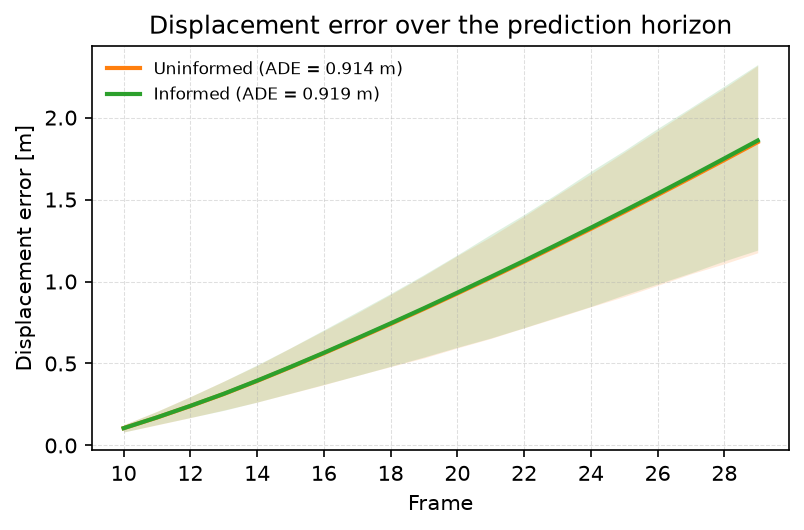

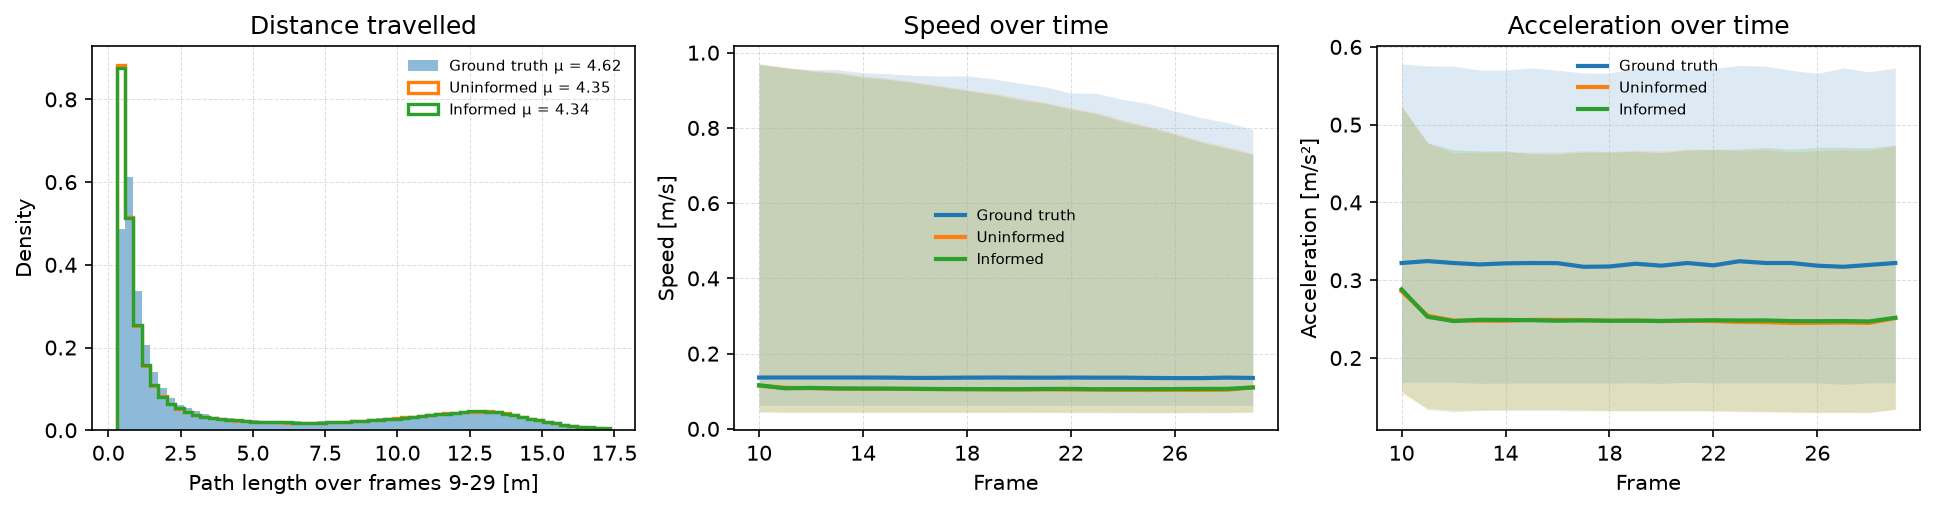

Binned KL(model || ground truth) [nats]          speed  acceleration    tortuosity       closest
Uninformed                                      0.0210        0.0880        0.0133        0.0322
Informed                                        0.0197        0.0879        0.0193        0.0328
Collision rate at r = 0.30 m
  Ground truth             0.6367%


  Uninformed               2.5749%


  Informed                 2.6081%


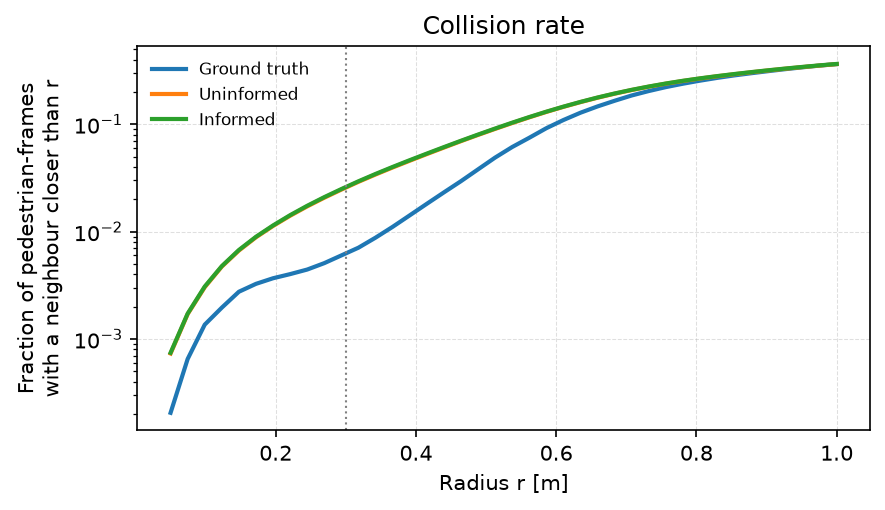

Transport cost E||x_0 - x_1||^2 per pedestrian (noise floor 2Kσ² = 40.000)
  Uninformed               77.549   above floor: 37.549
  Informed                 65.451   above floor: 25.451


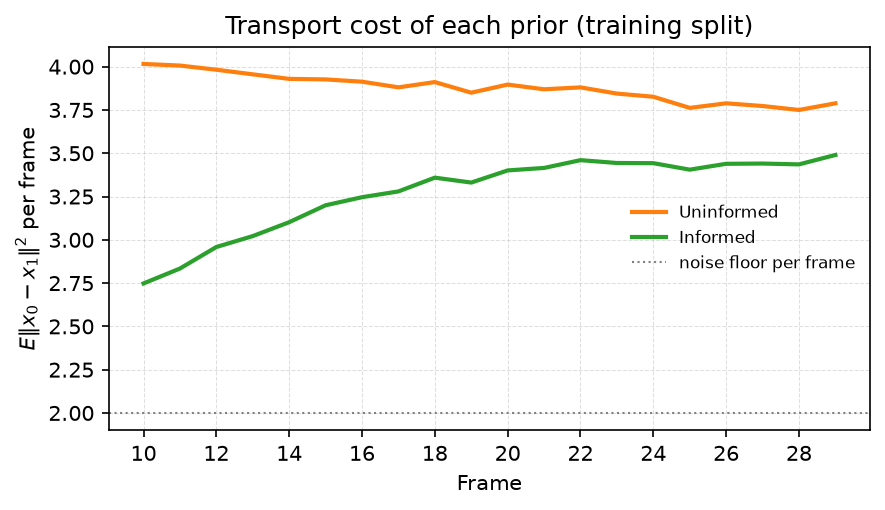

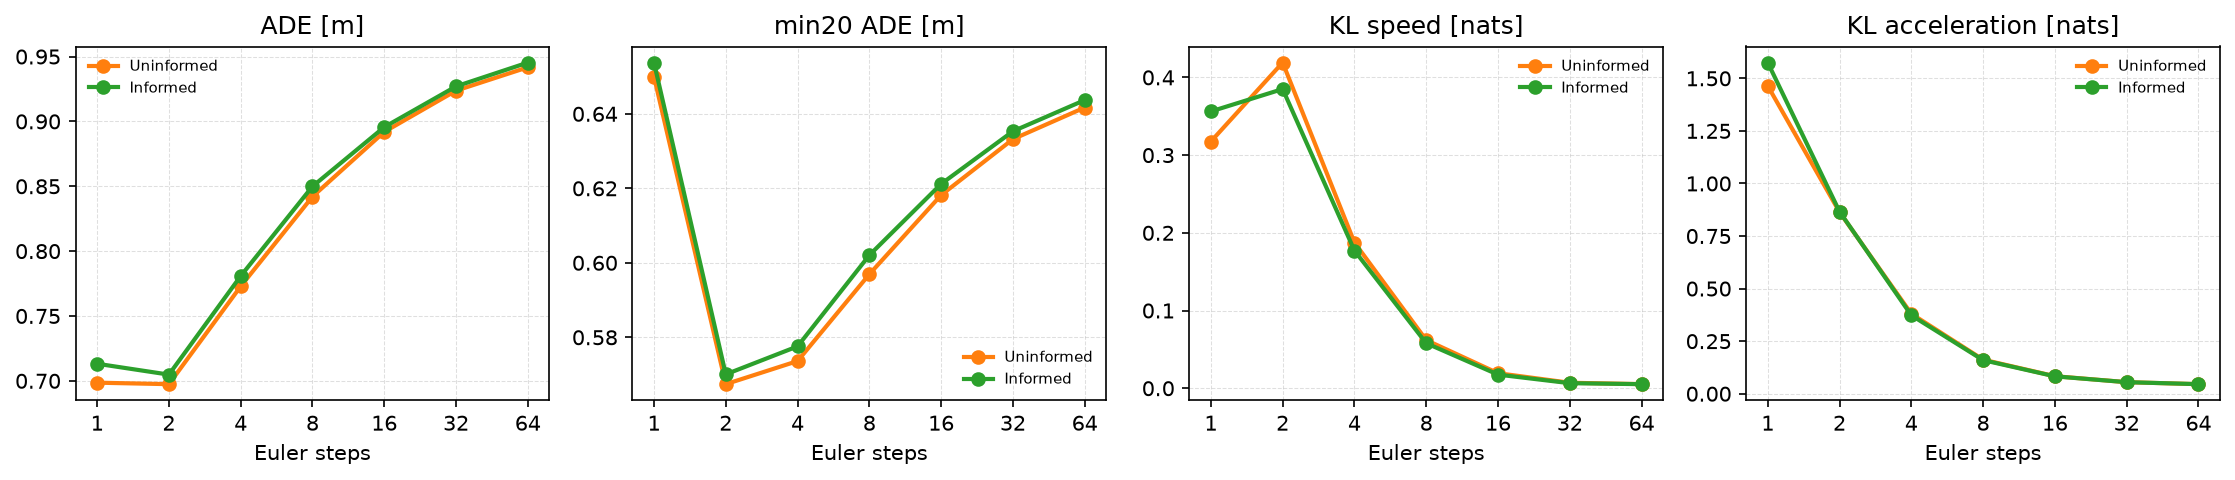

In [12]:
# 1. Error over the prediction horizon
errors = {"Uninformed": displacement_error_per_frame(gt_test, gen_u),
          "Informed": displacement_error_per_frame(gt_test, gen_i)}
plot_error_over_horizon(errors)
plt.show()

# 2. Distance travelled and kinematics over time
plot_distance_and_time_profiles(all_kins)
plt.show()

# 3. Binned KL divergence for the four histograms
kl_results = kl_table(gt_kin, model_kins)

# 4. Collision rate
plot_collision_rate(all_kins)
plt.show()

# 5. Transport cost of each prior, on the training split
costs = prior_transport_cost({"Uninformed": prior_uninformed, "Informed": prior_informed},
                             target_fn, data_module.train_dataloader())
report_transport_cost(costs, sigma=SIGMA)
plt.show()

# 6. Number of Euler steps, on 200 test samples
sweep_results, _ = euler_step_sweep({"Uninformed": sample_uninformed, "Informed": sample_informed},
                                    data_module.test_dataloader(), max_samples=200, gt_kin=None)
plt.show()